Mean Squared Error: 10.710864418838366
R2 Score: 0.7901500386760351

Feature Coefficients:
cylinders      -0.345789
horsepower     -0.021302
weight         -0.006142
displacement    0.015109
acceleration    0.037950
model_year      0.767743
origin          1.613457
dtype: float64


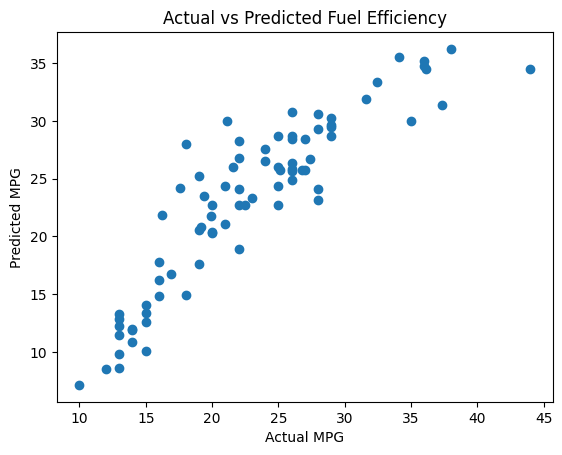

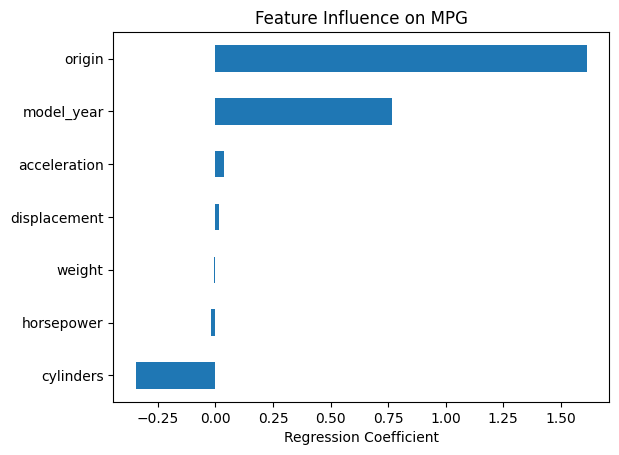

In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load Automobile MPG dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

columns = [
    'mpg', 'cylinders', 'displacement', 'horsepower',
    'weight', 'acceleration', 'model_year', 'origin', 'car_name'
]

df = pd.read_csv(
    url,
    sep=r'\s+',
    names=columns,
    na_values='?',
    comment='\t',
    skipinitialspace=True
)

df = df.dropna()

# Select input and output
X = df.drop(columns=['mpg', 'car_name'])
y = df['mpg']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluation
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

print("\nFeature Coefficients:")
print(pd.Series(model.coef_, index=X.columns).sort_values())

# Actual vs Predicted graph
plt.scatter(y_test, y_pred)
plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted Fuel Efficiency")
plt.show()

# Feature influence graph
pd.Series(model.coef_, index=X.columns).sort_values().plot(kind='barh')
plt.title("Feature Influence on MPG")
plt.xlabel("Regression Coefficient")
plt.show()
